Train subset size : 6000
Test subset size  : 1000
One image shape   : (1, 28, 28)
One label         : 7


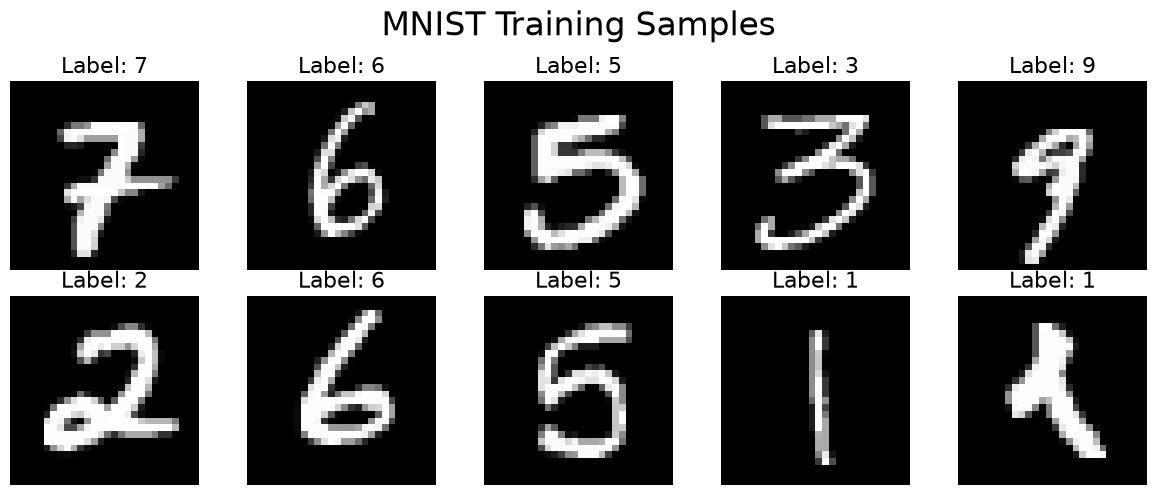

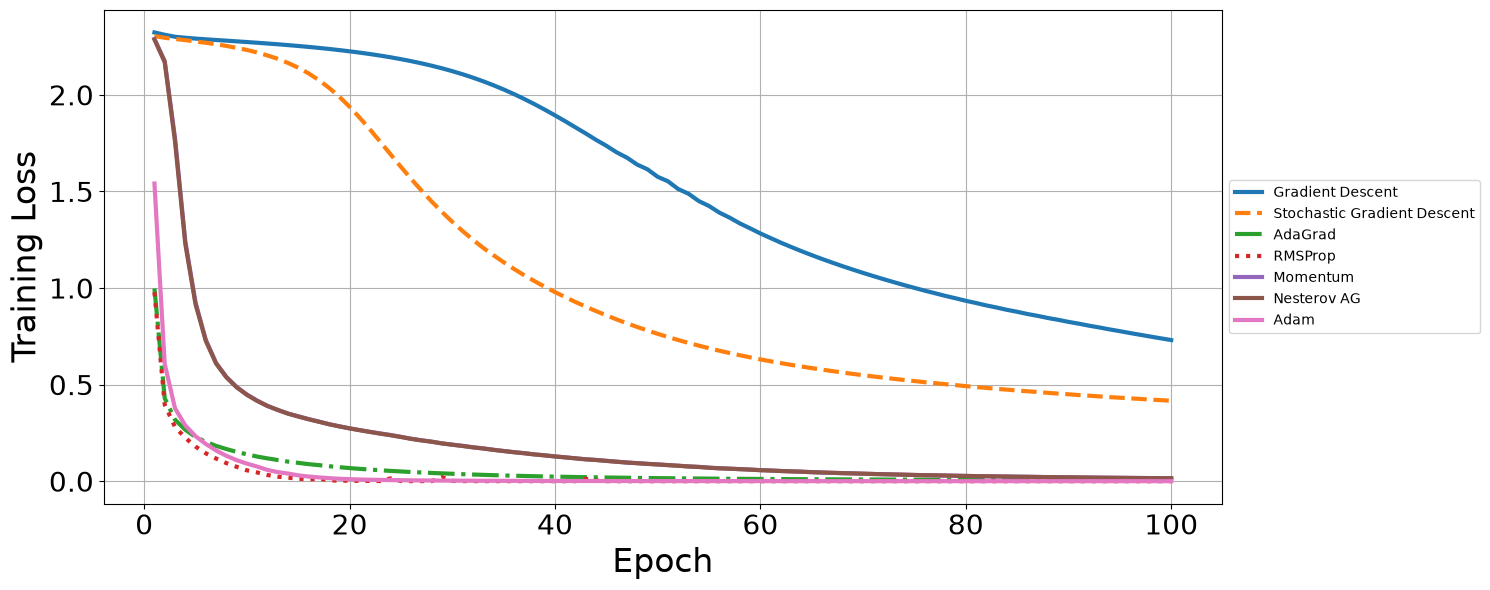

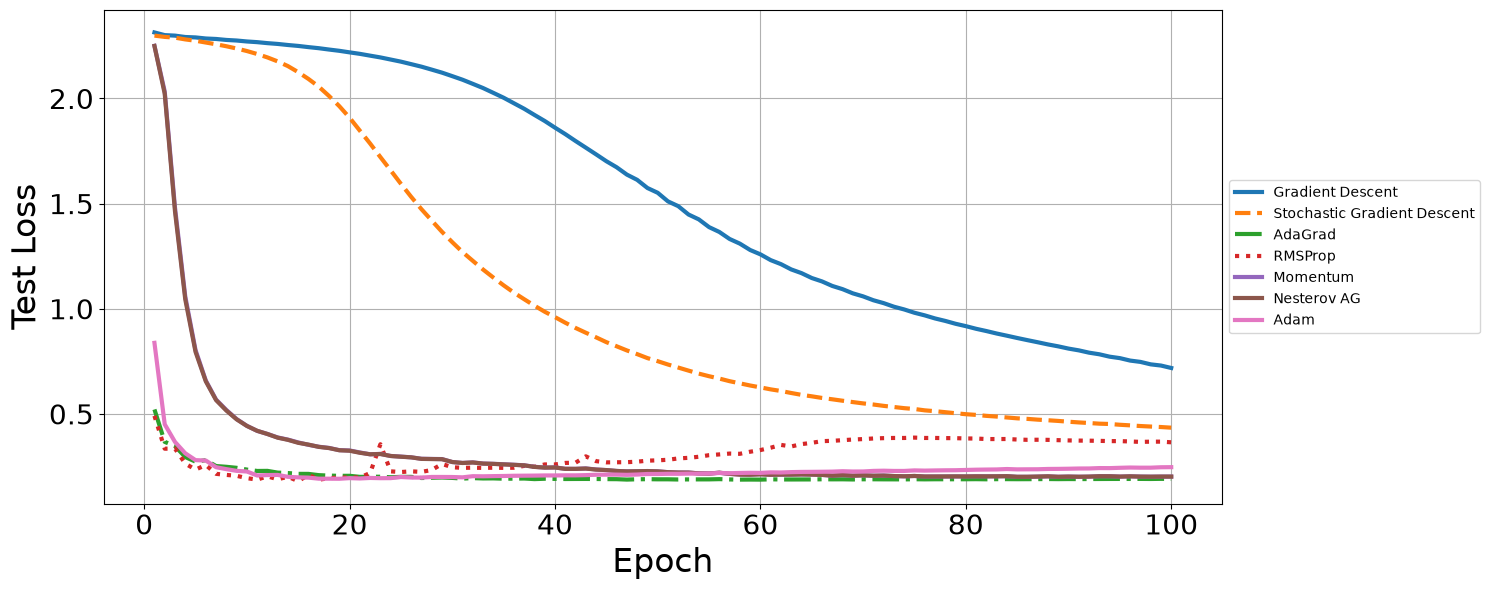

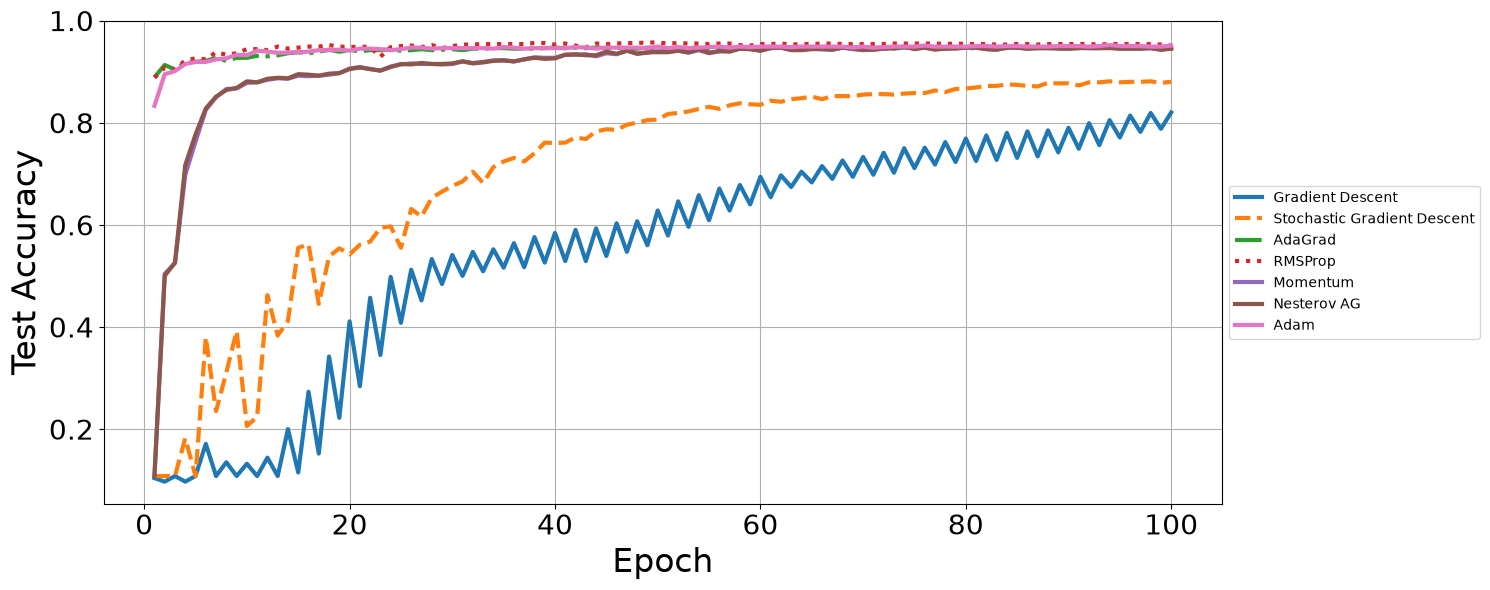

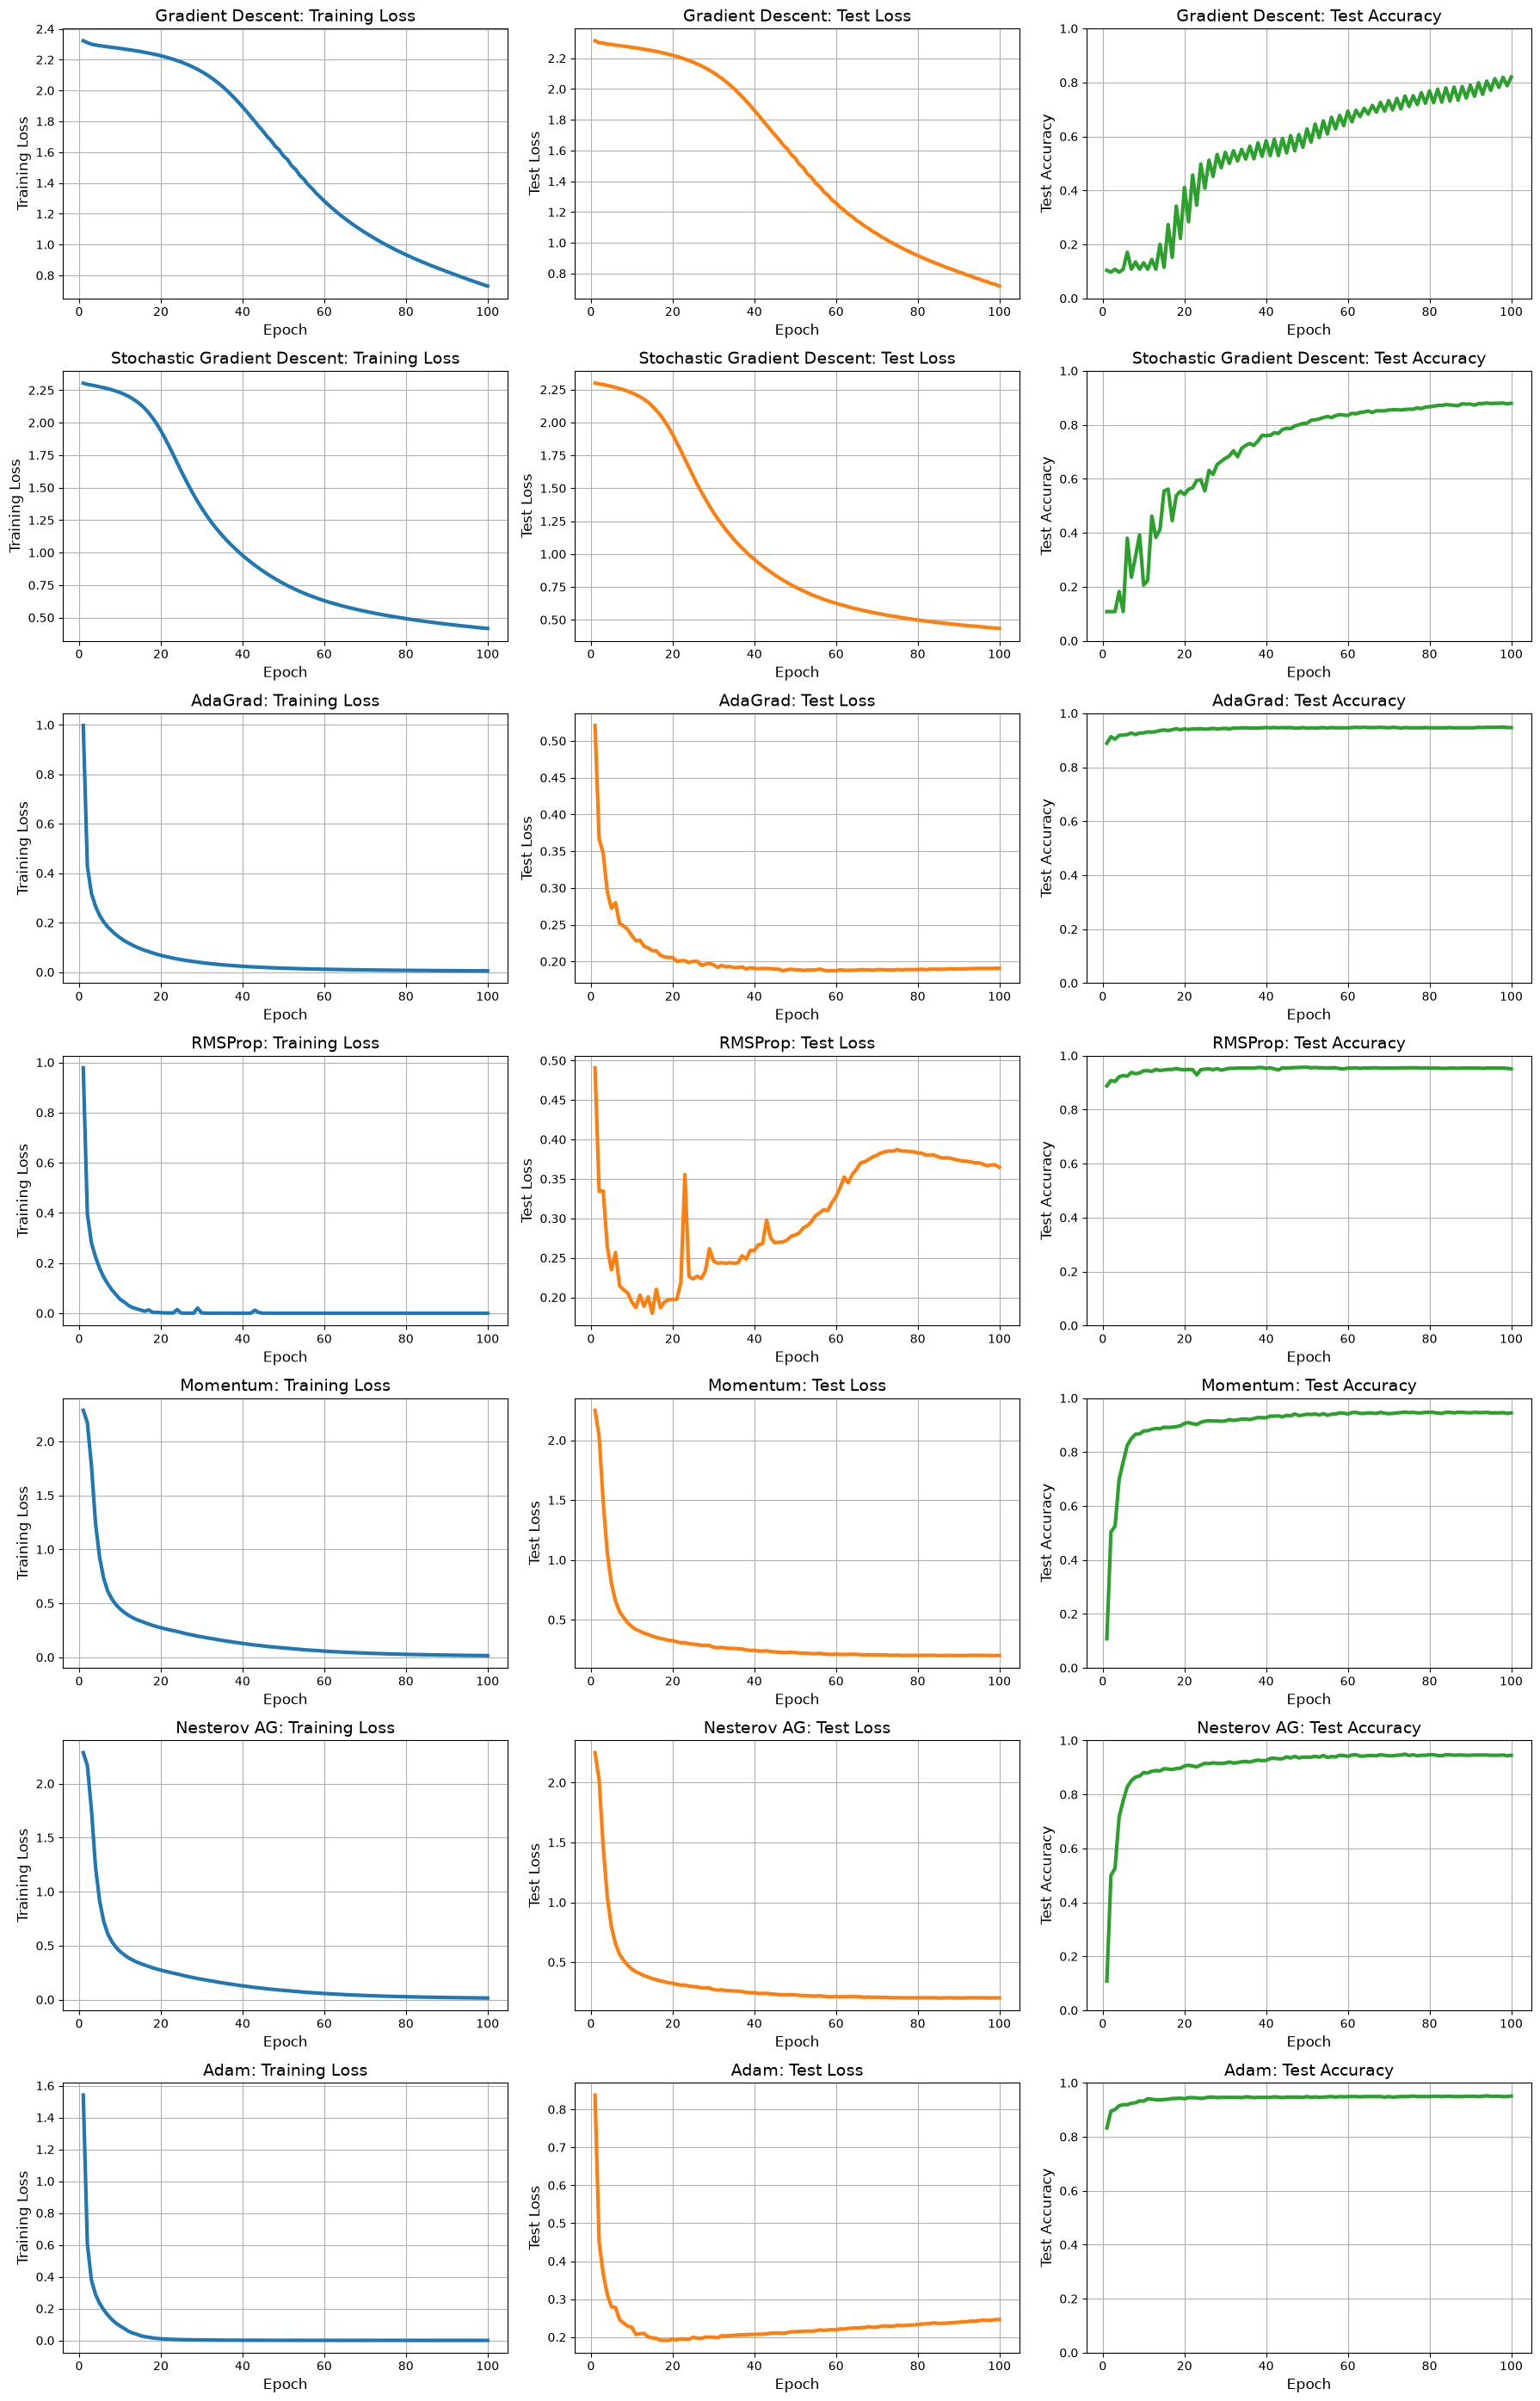

Optimizer                       Train Loss   Test Loss  Test Acc  Best Acc
RMSProp                             0.0000      0.3647    95.10%    95.70%
Adam                                0.0000      0.2465    95.10%    95.20%
AdaGrad                             0.0050      0.1905    94.70%    94.90%
Momentum                            0.0152      0.2018    94.50%    94.80%
Nesterov AG                         0.0151      0.2015    94.50%    94.90%
Stochastic Gradient Descent         0.4162      0.4343    88.00%    88.10%
Gradient Descent                    0.7304      0.7182    82.00%    82.00%


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------
# 1. Prepare Random Subsets
# -------------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
full_test  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_subset, _ = random_split(full_train, [6000, len(full_train) - 6000])
test_subset,  _ = random_split(full_test,  [1000, len(full_test)  - 1000])

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_subset,  batch_size=1000, shuffle=False)

# -------------------------------
# 2. Model
# -------------------------------
class SimpleMLP(nn.Module):
    def __init__(self, hidden1=256, hidden2=128):
        super().__init__()
        self.fc1 = nn.Linear(28*28, hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.fc3 = nn.Linear(hidden2, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = torch.sigmoid(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        return self.fc3(x)

# -------------------------------
# 3. Training helpers, for example. You can implement your own as needed.
# -------------------------------
def train_epoch(model, device, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * xb.size(0)
    return running_loss / len(loader.dataset)

def eval_model(model, device, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            running_loss += criterion(logits, yb).item() * xb.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == yb).sum().item()
    avg_loss = running_loss / len(loader.dataset)
    accuracy = correct / len(loader.dataset)
    return avg_loss, accuracy

# 4. Implementing optimizer, training, and analysis.
#######################

# ===============================
#  Visualize the Data
# ===============================
torch.manual_seed(0)
np.random.seed(0)

device = torch.device('cpu')

# -------------------------------
# Inspect the Dataset Structure
# -------------------------------
sample_x, sample_y = train_subset[0]
print('Train subset size :', len(train_subset))
print('Test subset size  :', len(test_subset))
print('One image shape   :', tuple(sample_x.shape))  
print('One label         :', sample_y)

# -------------------------------
#Visualize a few samples of the data  
# -------------------------------
mean, std = 0.1307, 0.3081  #
plt.figure(figsize=(12, 5))
for i in range(10):
    img, label = train_subset[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(img.squeeze() * std + mean, cmap='gray')
    plt.title(f'Label: {label}', fontsize=16)
    plt.axis('off')
plt.suptitle('MNIST Training Samples', fontsize=24)
plt.tight_layout()
plt.show()


# ===============================
# 4b. Step 2: Training Utilities
# ===============================

full_batch_loader = DataLoader(train_subset, batch_size=len(train_subset), shuffle=True)

criterion = nn.CrossEntropyLoss()


def get_model():
    torch.manual_seed(0)
    return SimpleMLP().to(device)

# -------------------------------
# Training Function
# -------------------------------
def train_model(model, optimizer, loader, epochs):
    history = {'train_loss': [], 'test_loss': [], 'test_acc': []}
    for epoch in range(epochs):
        train_loss = train_epoch(model, device, loader, optimizer, criterion)
        test_loss, test_acc = eval_model(model, device, test_loader, criterion)
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
    return history

# ===============================
# 4c. Step 2: Train with Each Optimizer
# ===============================
def run_one_setup(epochs):
  results = {}

  # -------------------------------
  # 1. Gradient Descent (GD) - Full Batch
  # -------------------------------
  model = get_model()
  optimizer_gd = optim.SGD(model.parameters(), lr=0.5)  # full batch
  results['Gradient Descent'] = train_model(model, optimizer_gd, full_batch_loader, epochs)

  # -------------------------------
  # 2. Stochastic Gradient Descent (SGD) - Mini-batches
  # -------------------------------
  model = get_model()
  optimizer_sgd = optim.SGD(model.parameters(), lr=0.01)  # using mini-batches
  results['Stochastic Gradient Descent'] = train_model(model, optimizer_sgd, train_loader, epochs)

  # -------------------------------
  # 3. AdaGrad
  # -------------------------------
  model = get_model()
  optimizer_adagrad = optim.Adagrad(model.parameters(), lr=0.01)
  results['AdaGrad'] = train_model(model, optimizer_adagrad, train_loader, epochs)

  # -------------------------------
  # 4. RMSProp
  # -------------------------------
  model = get_model()
  optimizer_rmsprop = optim.RMSprop(model.parameters(), lr=0.001)
  results['RMSProp'] = train_model(model, optimizer_rmsprop, train_loader, epochs)

  # -------------------------------
  # 5. SGD with Momentum
  # -------------------------------
  model = get_model()
  optimizer_momentum = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
  results['Momentum'] = train_model(model, optimizer_momentum, train_loader, epochs)

  # -------------------------------
  # 6. Nesterov Accelerated Gradient
  # -------------------------------
  model = get_model()
  optimizer_nesterov = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)
  results['Nesterov AG'] = train_model(model, optimizer_nesterov, train_loader, epochs)

  # -------------------------------
  # 7. Adam
  # -------------------------------
  model = get_model()
  optimizer_adam = optim.Adam(model.parameters(), lr=0.001)
  results['Adam'] = train_model(model, optimizer_adam, train_loader, epochs)

  return results

# -------------------------------
# Set epochs to 100
# -------------------------------
epochs = 100
results = run_one_setup(epochs)

# ===============================
# Step 3: Plot Training Loss, Test Loss, and Accuracy

epochs_range = np.arange(1, epochs + 1)
train_losses = {name: h['train_loss'] for name, h in results.items()}
test_losses  = {name: h['test_loss']  for name, h in results.items()}
test_accs    = {name: h['test_acc']   for name, h in results.items()}

# -------------------------------
# Plotting Training Loss vs Epochs
# -------------------------------
plt.figure(figsize=(15, 6))

plt.plot(epochs_range, train_losses['Gradient Descent'], label='Gradient Descent', linewidth=3)
plt.plot(epochs_range, train_losses['Stochastic Gradient Descent'], label='Stochastic Gradient Descent', linestyle='--', linewidth=3)
plt.plot(epochs_range, train_losses['AdaGrad'], label='AdaGrad', linestyle='-.', linewidth=3)
plt.plot(epochs_range, train_losses['RMSProp'], label='RMSProp', linestyle=':', linewidth=3)
plt.plot(epochs_range, train_losses['Momentum'], label='Momentum', linewidth=3)
plt.plot(epochs_range, train_losses['Nesterov AG'], label='Nesterov AG', linewidth=3)
plt.plot(epochs_range, train_losses['Adam'], label='Adam', linewidth=3)

plt.xlabel('Epoch', fontsize=24)
plt.ylabel('Training Loss', fontsize=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# Plotting Test Loss vs Epochs
# -------------------------------
plt.figure(figsize=(15, 6))

plt.plot(epochs_range, test_losses['Gradient Descent'], label='Gradient Descent', linewidth=3)
plt.plot(epochs_range, test_losses['Stochastic Gradient Descent'], label='Stochastic Gradient Descent', linestyle='--', linewidth=3)
plt.plot(epochs_range, test_losses['AdaGrad'], label='AdaGrad', linestyle='-.', linewidth=3)
plt.plot(epochs_range, test_losses['RMSProp'], label='RMSProp', linestyle=':', linewidth=3)
plt.plot(epochs_range, test_losses['Momentum'], label='Momentum', linewidth=3)
plt.plot(epochs_range, test_losses['Nesterov AG'], label='Nesterov AG', linewidth=3)
plt.plot(epochs_range, test_losses['Adam'], label='Adam', linewidth=3)

plt.xlabel('Epoch', fontsize=24)
plt.ylabel('Test Loss', fontsize=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# Plotting Test Accuracy vs Epochs
# -------------------------------
plt.figure(figsize=(15, 6))

plt.plot(epochs_range, test_accs['Gradient Descent'], label='Gradient Descent', linewidth=3)
plt.plot(epochs_range, test_accs['Stochastic Gradient Descent'], label='Stochastic Gradient Descent', linestyle='--', linewidth=3)
plt.plot(epochs_range, test_accs['AdaGrad'], label='AdaGrad', linestyle='-.', linewidth=3)
plt.plot(epochs_range, test_accs['RMSProp'], label='RMSProp', linestyle=':', linewidth=3)
plt.plot(epochs_range, test_accs['Momentum'], label='Momentum', linewidth=3)
plt.plot(epochs_range, test_accs['Nesterov AG'], label='Nesterov AG', linewidth=3)
plt.plot(epochs_range, test_accs['Adam'], label='Adam', linewidth=3)

plt.xlabel('Epoch', fontsize=24)
plt.ylabel('Test Accuracy', fontsize=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# Plotting Each Optimizer Separately
# -------------------------------
fig, axes = plt.subplots(len(results), 3, figsize=(18, 4 * len(results)))
for row, name in enumerate(results):
    axes[row, 0].plot(epochs_range, train_losses[name], linewidth=3, color='C0')
    axes[row, 0].set_title(f'{name}: Training Loss', fontsize=14)
    axes[row, 0].set_ylabel('Training Loss', fontsize=12)

    axes[row, 1].plot(epochs_range, test_losses[name], linewidth=3, color='C1')
    axes[row, 1].set_title(f'{name}: Test Loss', fontsize=14)
    axes[row, 1].set_ylabel('Test Loss', fontsize=12)

    axes[row, 2].plot(epochs_range, test_accs[name], linewidth=3, color='C2')
    axes[row, 2].set_title(f'{name}: Test Accuracy', fontsize=14)
    axes[row, 2].set_ylabel('Test Accuracy', fontsize=12)
    axes[row, 2].set_ylim(0, 1)

    for ax in axes[row]:
        ax.set_xlabel('Epoch', fontsize=12)
        ax.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# Final-Epoch Summary
# -------------------------------
print(f"{'Optimizer':<30}{'Train Loss':>12}{'Test Loss':>12}{'Test Acc':>10}{'Best Acc':>10}")
for name, history in sorted(results.items(), key=lambda kv: -kv[1]['test_acc'][-1]):
    print(f"{name:<30}{history['train_loss'][-1]:>12.4f}{history['test_loss'][-1]:>12.4f}"
          f"{history['test_acc'][-1]:>10.2%}{max(history['test_acc']):>10.2%}")
#######################